# Capítulo 11 — Modelo 1: Árvore de Decisão

**Apoio a Fabio · FarmTech Solutions**

Este notebook reutiliza `cap11/modelagem.py`: mesmas sete features, target `label`, split estratificado 80/20 com `random_state=42`, `StandardScaler` dentro do pipeline e validação cruzada `StratifiedKFold` de cinco folds. O teste fica reservado para avaliação final.

## 1. Dados e preparação compartilhada

A origem é o CSV oficial em `cap11/data/Atividade_Cap11_produtos_agricolas.csv`. Nenhuma cópia ou preparação alternativa é criada.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate

raiz = Path.cwd()
CAP11_DIR = next(p for p in [raiz / 'cap11', raiz] if (p / 'modelagem.py').is_file())
if str(CAP11_DIR) not in sys.path: sys.path.insert(0, str(CAP11_DIR))
from modelagem import FEATURES, TARGET, RANDOM_STATE, METRICS, carregar_dataset, separar_treino_teste, construir_pipeline, criar_validacao_cruzada, criar_tabela_comparacao, configurar_estilo_graficos
configurar_estilo_graficos()
CAMINHO_CSV = CAP11_DIR / 'data' / 'Atividade_Cap11_produtos_agricolas.csv'
dados = carregar_dataset(CAMINHO_CSV)
print(f'Dataset: {CAMINHO_CSV}; dimensões: {dados.shape}')
print('Features:', FEATURES, '| Target:', TARGET)
display(dados.head())
assert dados.columns.tolist() == FEATURES + [TARGET] and not dados.empty
particoes = separar_treino_teste(dados, random_state=RANDOM_STATE)
X_train, X_test = particoes.X_train, particoes.X_test
y_train, y_test = particoes.y_train, particoes.y_test
print(f'Treino: {len(X_train)}; teste: {len(X_test)}; índices sobrepostos: {bool(set(X_train.index) & set(X_test.index))}')
assert list(X_train.columns) == FEATURES and TARGET not in X_train.columns
assert X_test.index.equals(separar_treino_teste(dados).X_test.index)
assert not (set(X_train.index) & set(X_test.index))

Dataset: cap11/data/Atividade_Cap11_produtos_agricolas.csv; dimensões: (2200, 8)
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'] | Target: label


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Treino: 1760; teste: 440; índices sobrepostos: False


## 2. Modelo e validação cruzada

Uma Árvore de Decisão divide recursivamente o espaço de atributos em regiões, escolhendo regras que reduzem a impureza. Ela captura relações não lineares e é interpretável, mas uma árvore profunda pode memorizar o treino. Usamos `DecisionTreeClassifier(random_state=42)` com hiperparâmetros padrão; nenhuma escolha considera o teste. O `StandardScaler` permanece no pipeline comum, embora escala não seja necessária matematicamente para árvores.

In [2]:
modelo_arvore = construir_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
scoring = {'accuracy':'accuracy', 'precision_macro':'precision_macro', 'recall_macro':'recall_macro', 'f1_macro':'f1_macro'}
resultado_cv = cross_validate(modelo_arvore, X_train, y_train, cv=criar_validacao_cruzada(), scoring=scoring, return_train_score=False, n_jobs=1)
resumo_cv = pd.DataFrame({'média':[resultado_cv[f'test_{m}'].mean() for m in METRICS], 'desvio padrão':[resultado_cv[f'test_{m}'].std(ddof=1) for m in METRICS]}, index=METRICS)
display(resumo_cv.style.format('{:.4f}'))

,média,desvio padrão
accuracy,0.9852,0.0076
precision_macro,0.9863,0.0071
recall_macro,0.9852,0.0076
f1_macro,0.9852,0.0076


## 3. Avaliação final no teste

Após a validação cruzada, ajustamos o pipeline em todo o treino e avaliamos uma única vez o teste compartilhado. A diferença treino-teste é um sinal descritivo, não um teste formal de overfitting.

,treino (referência),teste,diferença treino − teste
accuracy,1.0000,0.9795,0.0205
precision_macro,1.0000,0.9806,0.0194
recall_macro,1.0000,0.9795,0.0205
f1_macro,1.0000,0.9794,0.0206


No teste: Accuracy **0.9795**, Precision macro **0.9806**, Recall macro **0.9795**, F1 macro **0.9794**.

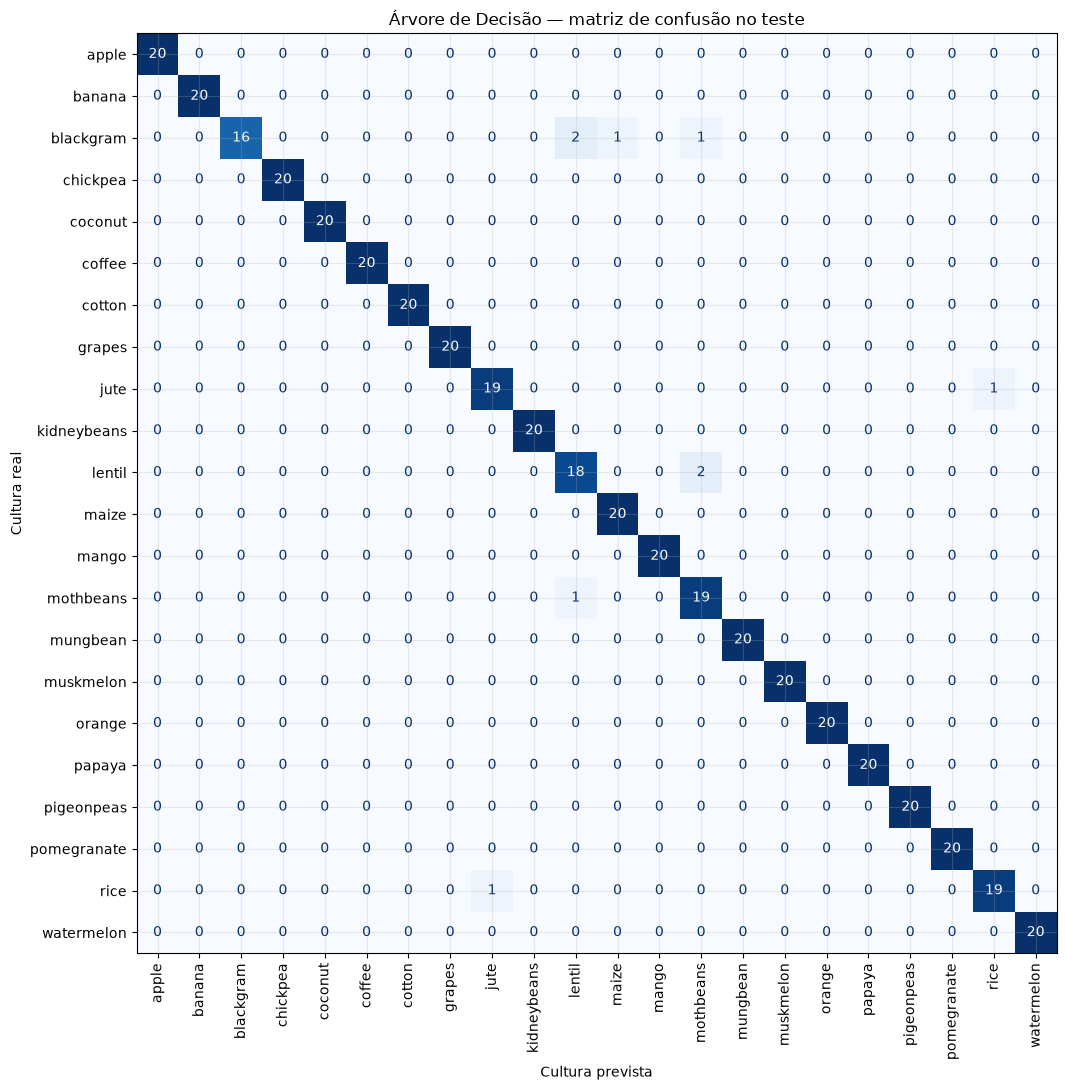

,cultura real,prevista como,registros
0,blackgram,lentil,2
1,lentil,mothbeans,2
2,blackgram,maize,1
3,blackgram,mothbeans,1
4,jute,rice,1
5,mothbeans,lentil,1
6,rice,jute,1


In [3]:
modelo_arvore.fit(X_train, y_train)
predicoes_teste = modelo_arvore.predict(X_test)
predicoes_treino = modelo_arvore.predict(X_train)
def calcular_metricas(y_real, y_previsto):
    return {'accuracy':accuracy_score(y_real,y_previsto), 'precision_macro':precision_score(y_real,y_previsto,average='macro',zero_division=0), 'recall_macro':recall_score(y_real,y_previsto,average='macro',zero_division=0), 'f1_macro':f1_score(y_real,y_previsto,average='macro',zero_division=0)}
metricas_teste = calcular_metricas(y_test, predicoes_teste)
metricas_treino = calcular_metricas(y_train, predicoes_treino)
tabela_metricas = pd.DataFrame({'treino (referência)':metricas_treino,'teste':metricas_teste})
tabela_metricas['diferença treino − teste'] = tabela_metricas['treino (referência)'] - tabela_metricas['teste']
display(tabela_metricas.style.format('{:.4f}'))
assert len(predicoes_teste)==len(y_test) and all(np.isfinite(v) and 0<=v<=1 for v in metricas_teste.values())
display(Markdown(f"No teste: Accuracy **{metricas_teste['accuracy']:.4f}**, Precision macro **{metricas_teste['precision_macro']:.4f}**, Recall macro **{metricas_teste['recall_macro']:.4f}**, F1 macro **{metricas_teste['f1_macro']:.4f}**."))
ordem_classes = sorted(dados[TARGET].unique())
matriz_confusao = confusion_matrix(y_test, predicoes_teste, labels=ordem_classes)
fig, ax = plt.subplots(figsize=(13,11))
ConfusionMatrixDisplay(matriz_confusao, display_labels=ordem_classes).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d',xticks_rotation=90)
ax.set_title('Árvore de Decisão — matriz de confusão no teste'); ax.set_xlabel('Cultura prevista'); ax.set_ylabel('Cultura real'); fig.tight_layout(); plt.show()
assert matriz_confusao.shape==(len(ordem_classes),len(ordem_classes)) and int(matriz_confusao.sum())==len(y_test)
pares_confusao = pd.DataFrame([{'cultura real':ordem_classes[i],'prevista como':ordem_classes[j],'registros':int(matriz_confusao[i,j])} for i in range(len(ordem_classes)) for j in range(len(ordem_classes)) if i!=j and matriz_confusao[i,j]>0])
if not pares_confusao.empty: pares_confusao = pares_confusao.sort_values('registros',ascending=False,kind='stable').reset_index(drop=True)
display(pares_confusao.head(10))

## 4. Importância, exemplo real e análise de generalização

Importância por impureza descreve o uso das variáveis nesta árvore, não causalidade. Gap alto entre desempenho no treino, folds e teste pode indicar overfitting; resultados próximos reduzem esse sinal, sem descartá-lo.

,importância
rainfall,0.3543
P,0.2250
humidity,0.1493
K,0.1108
N,0.0988
temperature,0.0544
ph,0.0074


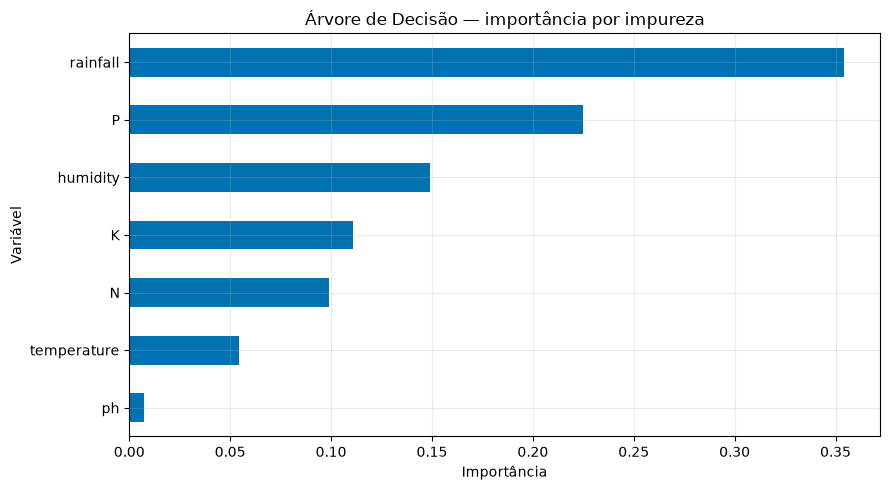

F1 treino 1.0000; teste 0.9794; gap 0.0206. F1 CV médio 0.9852 (DP 0.0076). O gap não sugere grande diferença nesta partição, embora não descarte overfitting em outros dados.

Índice real do teste: 1609 | classe verdadeira: orange | prevista: orange


,N,P,K,temperature,humidity,ph,rainfall
1609,13,23,6,23.961476,90.26408,7.365338,102.69587


In [4]:
importancias = pd.Series(modelo_arvore.named_steps['modelo'].feature_importances_,index=FEATURES,name='importância').sort_values(ascending=False)
display(importancias.to_frame().style.format('{:.4f}'))
fig, ax = plt.subplots(figsize=(9,5)); importancias.sort_values().plot(kind='barh',ax=ax,color='#0072B2'); ax.set_title('Árvore de Decisão — importância por impureza'); ax.set_xlabel('Importância'); ax.set_ylabel('Variável'); fig.tight_layout(); plt.show()
gap_f1 = metricas_treino['f1_macro'] - metricas_teste['f1_macro']
display(Markdown(f"F1 treino {metricas_treino['f1_macro']:.4f}; teste {metricas_teste['f1_macro']:.4f}; gap {gap_f1:.4f}. F1 CV médio {resultado_cv['test_f1_macro'].mean():.4f} (DP {resultado_cv['test_f1_macro'].std(ddof=1):.4f}). {'O gap recomenda atenção a possível overfitting.' if gap_f1 > .05 else 'O gap não sugere grande diferença nesta partição, embora não descarte overfitting em outros dados.'}"))
indice_exemplo = X_test.index[0]; linha_exemplo = X_test.loc[[indice_exemplo]]
print('Índice real do teste:',indice_exemplo,'| classe verdadeira:',y_test.loc[indice_exemplo],'| prevista:',modelo_arvore.predict(linha_exemplo)[0]); display(linha_exemplo)
assert indice_exemplo in X_test.index

## 5. Integração das métricas disponíveis

O dicionário usa as métricas calculadas para a árvore e os valores documentados no notebook executado de Random Forest. Os valores RF não são recalculados aqui. Nenhuma métrica é inventada para modelos pendentes.

In [5]:
resultados_disponiveis = {'Árvore de Decisão':metricas_teste, 'Random Forest':{'accuracy':0.9955,'precision_macro':0.9957,'recall_macro':0.9955,'f1_macro':0.9955}}
tabela_comparacao = criar_tabela_comparacao(resultados_disponiveis)
display(tabela_comparacao[METRICS].style.format('{:.4f}'))
modelos_pendentes = tabela_comparacao.attrs['modelos_pendentes']
print('Resultados disponíveis:',list(tabela_comparacao.index)); print('Aguardando:',modelos_pendentes)
assert set(tabela_comparacao.index)=={'Árvore de Decisão','Random Forest'}
assert modelos_pendentes==['Regressão Logística','SVM','Gradient Boosting']

,accuracy,precision_macro,recall_macro,f1_macro
Modelo,,,,
Árvore de Decisão,0.9795,0.9806,0.9795,0.9794
Random Forest,0.9955,0.9957,0.9955,0.9955


Resultados disponíveis: ['Árvore de Decisão', 'Random Forest']
Aguardando: ['Regressão Logística', 'SVM', 'Gradient Boosting']


## Conclusões e limitações

A árvore oferece regras interpretáveis e captura relações não lineares. Pode, porém, ser instável diante de pequenas mudanças e sobreajustar se crescer sem controle; importâncias por impureza também têm limitações. Interprete métricas e confusões junto ao gap treino-teste e à variação entre folds.

Os resultados descrevem somente este dataset e esta partição e não garantem desempenho em outras regiões ou safras. Ainda não declaramos se a árvore é melhor ou pior que os demais algoritmos. Faltam Regressão Logística, SVM e Gradient Boosting para a comparação final.